In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

In [ ]:
df = pd.read_csv("data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


In [23]:
metadata = Metadata.detect_from_dataframes(data={'comedian': df})
metadata.update_column(table_name='comedian', column_name='Nationality', sdtype='categorical')
metadata.update_column(table_name='comedian', column_name="Go", sdtype='categorical')

In [24]:
synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit({'comedian': df})
synthetic_data = synthesizer.sample(num_rows=100)['comedian']

c:\Users\personal-lap\AppData\Local\Programs\Python\Python312\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


In [25]:
df_augmented = pd.concat([df, synthetic_data], ignore_index=True)

In [26]:
df_augmented['Nationality'] = df_augmented['Nationality'].map({'UK': 0, 'USA': 1, 'N':2})
df_augmented['Go'] = df_augmented['Go'].map({"YES":1, "NO": 0})

In [27]:
print(df_augmented.isna().sum())
display(df_augmented)

Age            0
Experience     0
Rank           0
Nationality    0
Go             0
dtype: int64


,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
...,...,...,...,...,...
108,41,10,4,1,1
109,21,5,5,1,1
110,21,10,8,1,0
111,43,18,8,0,1


In [28]:
features = ['Age', 'Experience', 'Rank', 'Nationality']
X_aug = df_augmented[features]
y_aug = df_augmented['Go']

In [29]:
dtree_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
dtree_gini = dtree_gini.fit(X_aug.values, y_aug)

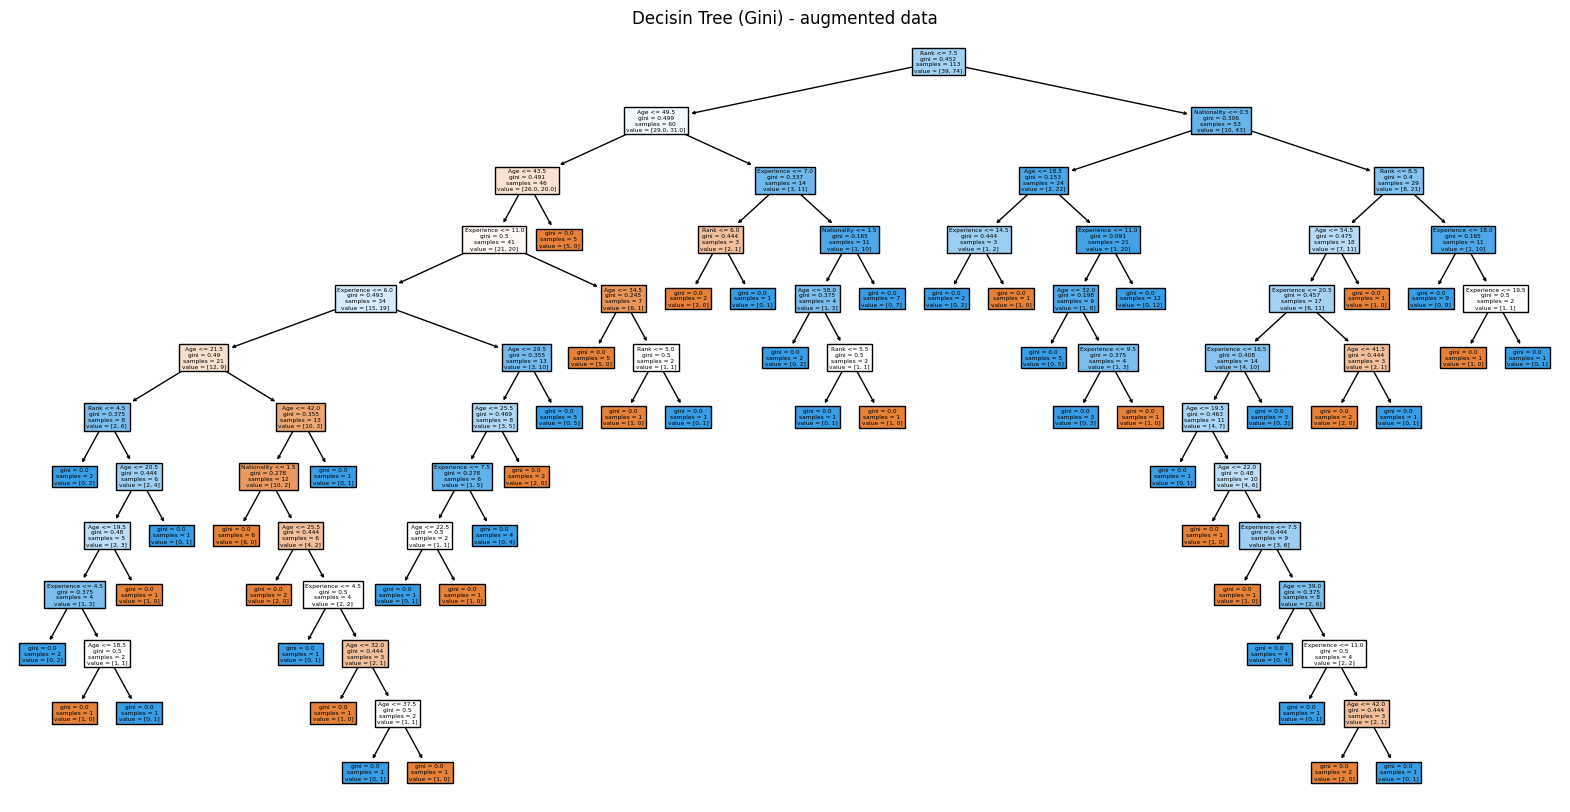

In [31]:
plt.figure(figsize=(20,10))
tree.plot_tree(dtree_gini, feature_names=features, filled=True)
plt.title("Decisin Tree (Gini) - augmented data")
plt.show()

In [32]:
dtree_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
dtree_entropy = dtree_entropy.fit(X_aug.values, y_aug)

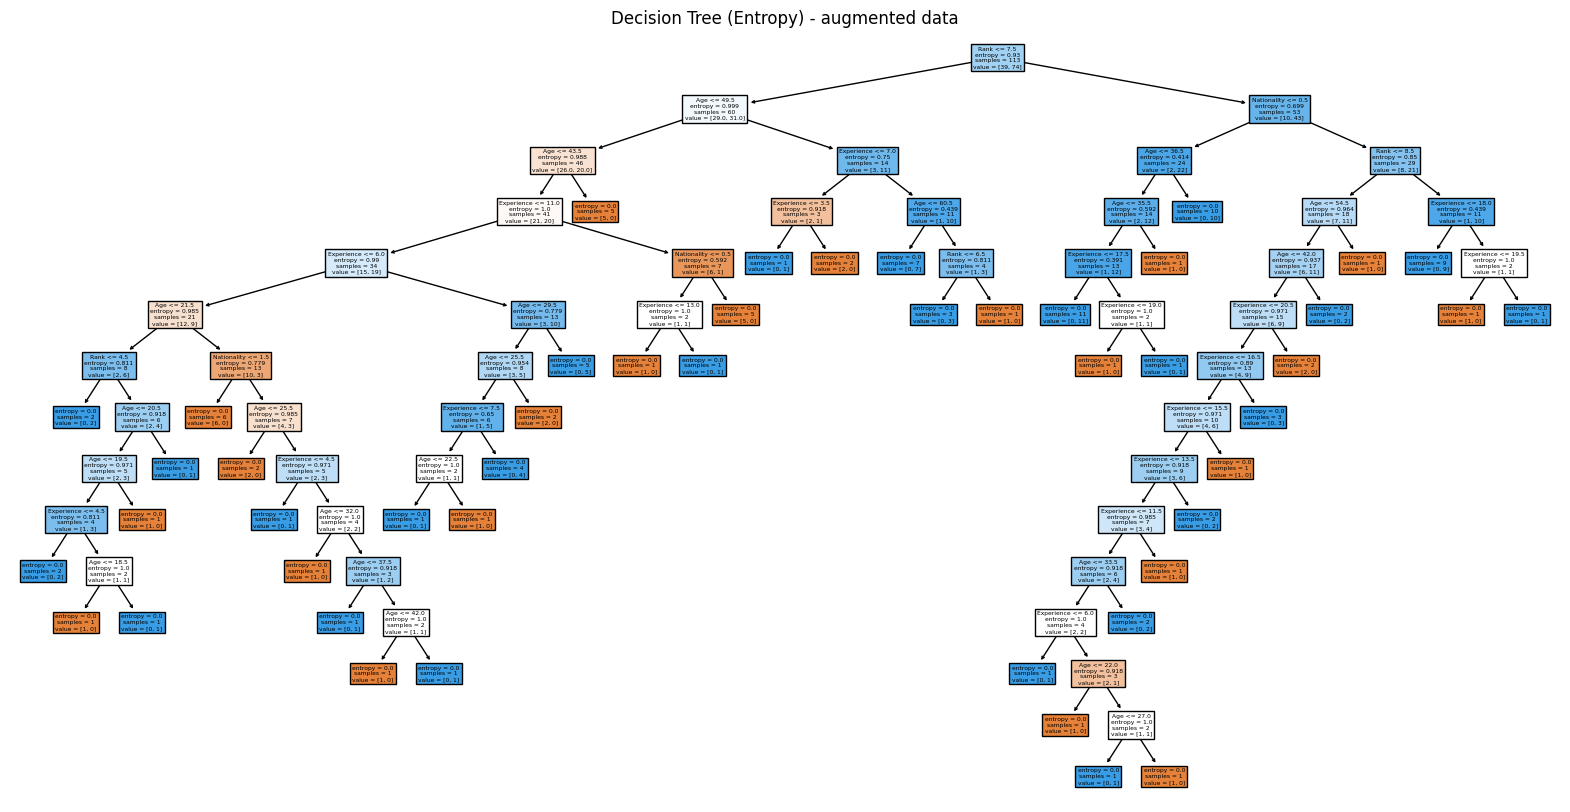

In [33]:
plt.figure(figsize=(20,10))
tree.plot_tree(dtree_entropy, feature_names=features, filled=True)
plt.title("Decision Tree (Entropy) - augmented data")
plt.show()

In [34]:
comparison = pd.DataFrame({
    'gini': dtree_gini.feature_importances_,
    'entropy': dtree_entropy.feature_importances_
}, index=features)
display(comparison)

,gini,entropy
Age,0.475755,0.424271
Experience,0.294719,0.360775
Rank,0.191186,0.140385
Nationality,0.038340,0.074568


In [37]:
print("Gini   ->  depth:", dtree_gini.get_depth(), "| leaves:", dtree_gini.get_n_leaves())
print("Entropy -> depth:", dtree_entropy.get_depth(), "| leaves:" ,dtree_entropy.get_n_leaves())

Gini   ->  depth: 12 | leaves: 48
Entropy -> depth: 14 | leaves: 47


## Answers to Questions

**What is Gini, and how does it work?**

Gini impurity measures the degree of "impurity" within a node:

$$Gini = 1 - \sum_{i=1}^{C} p_i^2$$

where $p_i$ is the proportion of samples belonging to class $i$ in that node, and $C$ is the number of classes. The Gini value is zero for a perfectly pure node (containing only one class) and 0.5 when there are two classes present in equal proportions. At each node, the tree selects a feature and a threshold that minimize the weighted average Gini impurity of the child nodes—effectively maximizing the reduction in impurity.

**How ​​do the tree structure and feature importance differ between the Gini and Entropy models?**

Instead of Gini, the Entropy criterion uses the following formula:

$$Entropy = -\sum_{i=1}^{C} p_i \log_2 p_i$$

In terms of structure, the Gini-based tree has a depth of 12 and 48 leaves, while the Entropy-based tree has a depth of 14 and 47 leaves; the number of leaves is roughly the same, though the Entropy tree is slightly deeper. Regarding feature importance, `Age` is the most significant feature in both models (0.476 for Gini vs. 0.424 for Entropy). The Entropy model assigns greater importance to `Experience` (0.361 vs. 0.295) and `Nationality` (0.075 vs. 0.038), while assigning less importance to `Rank` (0.140 vs. 0.191). Nevertheless, the overall ranking of feature importance remains identical across both models.

**Conclusion:** The choice of splitting criterion has a limited impact on the final outcome; differences are primarily observed in the structural details and the assigned feature weights. The significant depth (12 and 14) and the high number of leaf nodes in both trees—which is unusual for a dataset with only 13 primary rows—indicate that the models grew without constraints and essentially memorized the training data (overfitting). To address this issue, one could adjust parameters such as `max_depth` or `min_samples_leaf`.